In [ ]:
import numpy as np
import jax
import jax.numpy as jnp
from jax.numpy.linalg import norm
import jaxopt
import os
import nlopt

from AuxeticLib2Dv2 import *


class metamaterial():

    def __init__(self,filename,P=0):
        self.Ar=Auxetic(filename)
        self.N=len(self.Ar)
        if P==0:
            self.P=self.N #how many elements in one periodic box
        else:
            self.P=P
        self.Pb=self.N//self.P # how many periodic boxes
        self.Lx=self.Ar.Lx
        self.Ly=self.Ar.Ly
        
    def make_q_list(self):
        self.q=jnp.array(self.Ar.getVar())

    def make_poli_connectivity(self):
        Ar=self.Ar
        P=self.P
        #I leave for last conections between fixed polygons for that I use "valid" which is set by cutLink() 
        Cq=[] #Compatibility matrix/hash table
        Cvertex=[]
        mask_valid_bond=[]
        avecs=[]
        c=0
        Nb=0
        for poli in Ar:
            for pata in poli.patas:

                neigh=pata.myVecino
                pataN=pata.pataVecina
                i=poli.id
                j=neigh.id 
                if j%P>i%P: # 
                    if pataN.valid==0 or pata.valid==0:
                        mask_valid_bond.append(False)
                    else:
                        mask_valid_bond.append(True)
                        Nb+=1

                    avecs.append(pata.avec)
                    pata.vid=c
                    c+=1
                    avecs.append(pataN.avec)
                    pataN.vid=c
                    c+=1
                    Cq.append([i,j])
                    Cvertex.append([pata.vid,pataN.vid])
                    pata.id=[Nb,0] #no idea if this is broken (maybe these should go into the "else"?)
                    pataN.id=[Nb,1]
        self.Avecs=jnp.array(avecs)

        #Create NN array
        #generates ids of contact corners
        # Graphically these are the ids (p1 and p2 are stored in Cvertex)
        #
        #   0         1
        #     p1---p2
        #   3         2
        #
        neighIds1=[] #ids for Avecs -> AvecsNN
        neighIds2=[] #ids for AvecPairs -> AvecsNN
        for ij in Cq:
            i,j=ij
            poli1=Ar[i]
            poli2=Ar[j]
            for i,pata in enumerate(poli1.patas):
                if pata.myVecino==poli2:
                    pata1i=i
                    break
            for i,pata in enumerate(poli2.patas):
                if pata.myVecino==poli1:
                    pata2i=i
                    break
            n1=len(poli1.patas)
            n2=len(poli2.patas)
            neighIds1.append([(poli1.patas[(pata1i+1)%n1]).vid,(poli2.patas[(pata2i-1)%n2]).vid,(poli2.patas[(pata2i+1)%n2]).vid,(poli1.patas[(pata1i-1)%n1]).vid]) #vid 
            neighIds2.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id]) #id


        self.mask_valid_bond=jnp.array(mask_valid_bond)
        self.NbTotal=len(Cq)
        self.Nb=Nb #valid bonds
        self.PNbonds=self.NbTotal//self.Pb #number of bonds in one periodic box
        self.vs_index=jnp.tile(jnp.array(range(self.PNbonds*2)),self.Pb)#[jnp.repeat(self.mask_valid_bond,2)] #if we remove the filtering here and in Avecs, then all the bonds (even non valid) get deformed

        self.CqAll=jnp.array(Cq)
        self.Cq=jnp.array(Cq)[self.mask_valid_bond]
        self.CqIndex=jnp.concatenate([self.Cq*3,self.Cq*3+1,self.Cq*3+2],axis=1) #meant to evaluate directly unto q,q[CqIndex], results in data of structure [x1,x2,y1,y2,t1,t2]*Nb
        
        self.CvertexAll=jnp.array(Cvertex)
        self.Cvertex=jnp.array(Cvertex)[self.mask_valid_bond]
        self.AvecsPairs=self.Avecs[self.Cvertex]
        self.Ccorners=jnp.array(neighIds1)[self.mask_valid_bond]
        self.neighIds=jnp.array(neighIds2)[self.mask_valid_bond] #for potential without l0, corners are shared

        self.mask_relevantAvecs=jnp.full(len(self.Avecs),False)
        self.mask_relevantAvecs=self.mask_relevantAvecs.at[self.Cvertex.flatten()].set(True) # must be Cvertex[self.mask_valid_bond] 
        #these are in a "random order"
        #could index in a correct order?
        

                    
    def cutBoundary(self,axis): #axis is 'x' or 'y'
        Ar=self.Ar
        if axis not in {"x", "y"}:
            raise ValueError("axis must be 'x' or 'y'")
        if axis=='x':
            size=Ar.Lx
        if axis=='y':
            size=Ar.Ly
        boundaryPointer=[]
        Ar=self.Ar
        for poli in Ar:
            for pata in poli.patas:
                neigh=pata.myVecino
                poliD=getattr(poli,axis) #same as poli.x or poli.y
                neighD=getattr(neigh,axis)
                if np.abs(poliD-neighD)>0.5*size and poli.id>neigh.id: #pataN.valid==1 and pata.valid==1
                    boundaryPointer.append(poli)
                    boundaryPointer.append(neigh)
                    cutLinkV(poli,neigh) #DOES NOT REMOVE THE LINK, only sets valid=0
        return boundaryPointer

#carefull, for now it only works for usepoliID=True , as we need to find a solution for removing bonds for partial freezing of DoFs
    def setfixedDoF(self,indexList,usepoliId=False): #sets the mask_border, and also removes in between boundary bonds 
        mask_border=jnp.full(len(self.q),True)

        if usepoliId==False: #only freeze certain Dof of each poligon
            mask_border=mask_border.at[indexList].set(False)

        if usepoliId==True: #fully freeze all DoF of each poligon
            mask_border=mask_border.at[indexList*3+0].set(False)
            mask_border=mask_border.at[indexList*3+1].set(False)
            mask_border=mask_border.at[indexList*3+2].set(False)
            for i in indexList:
                poli=self.Ar[i]
                for pata in poli.patas:
                    neigh=pata.myVecino
                    pataN=pata.pataVecina
                    if neigh.id in indexList:
                        pata.valid=0
                        pataN.valid=0

        self.inv_mask_border=~mask_border
        self.mask_border=mask_border

    def makeModel(self,integrator,initialization_function):
        def model(parameters):
            new_arguments=initialization_function(parameters)
            return integrator(new_arguments)
        return model


    def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi/2 , pi*3/2)
        return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi/2) % (2*jnp.pi) - jnp.pi/2

    
    def make_initialization(self):
        indexmap1=jax.vmap(lambda x,y: x[y[0],y[1]],(None,0))
        indexmap=jax.vmap(indexmap1,(None,1),1) # Uses indexes from y, and elements from x, to create array.

        def init_avecs(parameters): #maybe meta doesnt need to be an argument, can be fixed from the definition
            mvs=parameters['vs']
            def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi/2 , pi*3/2)
                return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi/2) % (2*jnp.pi) - jnp.pi/2
            rvs=jnp.tile(mvs,self.P) #repeat P times
            vsx=rvs.at[0::2].get()
            vsy=rvs.at[1::2].get()
            nvs=jnp.stack((vsx,vsy),axis=1)
            rAvecs=self.AvecsPairs.at[:self.Nb].add(nvs[:,jnp.newaxis,:])
            rAvecsNN=indexmap(rAvecs,self.neighIds)
            rAvecs=rAvecs.at[:self.Nb].get()
            rAvecsNN=rAvecsNN.at[:self.Nb].get()
            betaMap=jax.vmap( lambda avec1,avec2,u1,d2,u2,d1: jnp.array([angleVecs(d2-avec2,u1-avec1),angleVecs(d1-avec1,u2-avec2)]))
            betas=betaMap(rAvecs[:,0],rAvecs[:,1],rAvecsNN[:,0],rAvecsNN[:,1],rAvecsNN[:,2],rAvecsNN[:,3])
            return {"rAvecs":rAvecs,"betas":betas}
        return init_avecs

    
    def makeIntegrator(self,potential,noise):
        self.keys= jax.random.split(self.ikey,len(self.strain_signs))

        optimizer=jaxopt.LBFGS(potential)#LBFGS(potential)#LBFGS(potential,tol=1e-10,maxiter=50000,min_stepsize=1e-10,maxls=100)


        def integrator(arguments):

            def strain_fun(q,args):

                strain_sign,key=args
                if noise!=0:
                    qrand=(jax.random.uniform(key,shape=(self.N*3,))-0.5)*noise
                    qrand=qrand.at[self.inv_mask_border].set(0.0)
                    q=q+qrand
                
                q=q+self.eps*strain_sign                 
                border=q.at[self.inv_mask_border].get()
                q_NoBorder=q.at[self.mask_border].get()

                q_NoBorder,_=optimizer.run(q_NoBorder,border=border,**arguments)#opt_loop(q_old)
                
                q=q.at[self.mask_border].set(q_NoBorder)

                return q,q

            _,qs=jax.lax.scan(strain_fun,self.q,(self.strain_signs,self.keys))

            return qs,arguments
        return integrator
    
    


    def plotvs(self,nvs,q):
        
        setvs=jnp.tile(nvs,self.P)

        Ar=self.Ar

        vsx=setvs.at[0::2].get()
        vsy=setvs.at[1::2].get()
        nvs=jnp.stack((vsx,vsy),axis=1)
        rAvecs=self.AvecsPairs.at[:self.Nb].add(nvs[:,jnp.newaxis,:])
        for k,ij in enumerate(self.Cq[:self.Nb]):
            i,j=ij
            poli1=Ar[i]
            poli2=Ar[j]
            for pata in poli1.patas:
                if pata.myVecino==poli2:
                    pata1=pata
                    break
            pata2=pata1.pataVecina
            pata1.avec0=rAvecs[k][0]#pata1.avec0+=nvs[k]
            pata2.avec0=rAvecs[k][1]#pata2.avec0+=nvs[k]

        Ar.setVar(q)
        plt.figure()

        for poli in Ar:
            
            avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
            color='C0'
            if poli.id in self.boundary:
                color='C3'
            if len(avecs)<3:
                avecs.append([poli.x,poli.y])
            avecs=np.array(avecs)
            plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
            #plt.text(poli.x,poli.y,str(poli.id),size=10)
        plt.axis('scaled')

    def makeVideo(self,nvs,qs,folder):
        Ar=self.Ar

        setvs=jnp.tile(nvs,self.P)
        vsx=setvs.at[0::2].get()
        vsy=setvs.at[1::2].get()
        nvs=jnp.stack((vsx,vsy),axis=1)
        rAvecs=self.AvecsPairs.at[:self.Nb].add(nvs[:,jnp.newaxis,:])
        for k,ij in enumerate(self.Cq[:self.Nb]):
            i,j=ij
            poli1=Ar[i]
            poli2=Ar[j]
            for pata in poli1.patas:
                if pata.myVecino==poli2:
                    pata1=pata
                    break
            pata2=pata1.pataVecina
            pata1.avec0=rAvecs[k][0]#pata1.avec0+=nvs[k]
            pata2.avec0=rAvecs[k][1]#pata2.avec0+=nvs[k]

        os.makedirs(folder)
        for j,q in enumerate(qs):
            Ar.setVar(q)
            self=Ar
            plt.figure()
            for poli in Ar:
                avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
                color='C0'
                if poli.id in self.boundary:
                    color='C3'
                if len(avecs)<3:
                    avecs.append([poli.x,poli.y])
                avecs=np.array(avecs)
                plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
            plt.axis('scaled')
            plt.xlim(-self.Lx*0.05,self.Lx*(1.05))
            plt.ylim(-self.Ly*0.1,self.Ly*(1.05))
            plt.axis('off')
            plt.savefig(folder+str(j)+'.png')
            plt.close()



    def makePotential(self,coeffs,PBC=False, Shearing=True):

        self.kl=coeffs['kl'] 
        self.ks =coeffs['ks']
        self.kt =coeffs['kt']
        self.kc=coeffs['kc']
        self.gamma =coeffs['gamma']
        self.t0 =coeffs['t0']
        
        #Create potential energy
        MpV = jax.vmap(jax.vmap(lambda x,y: x@y, (0,0), 0), (1,1), 1) #Operates Array of matrices N x [2 x [2 x 2]] with array of vectors N x [2 x [2]]
        def Rotation(theta):
            return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
        RotationM=jax.vmap(Rotation)

        def interaction_potential(q,Cij,rAvecsij,betasij,Kij): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
            ks=1.0
            kt=Kij
            i,j=Cij
            avec1,avec2=rAvecsij
            #u1,d2,u2,d1=rAvecsNN #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
            x1=q[3*i+0]
            y1=q[3*i+1]
            t1=q[3*i+2]
            x2=q[3*j+0]
            y2=q[3*j+1]
            t2=q[3*j+2]
            dl=jnp.array([x1-x2,y1-y2])
            if PBC==True:
                dl=dl.at[0].add(-self.Lx*jnp.round(dl.at[0].get()/self.Lx)) #Periodic Boundary conditions
            dX=dl+avec1-avec2
            dtheta=t1-t2
            cAngle1=betasij[0]+dtheta+self.t0
            cAngle2=betasij[1]-dtheta+self.t0
            if Shearing==True:
                dx=dX.at[0].get()
                dy=dX.at[1].get()
                dl=dl/jnp.linalg.norm(dl)
                dlx=dl.at[0].get()
                dly=dl.at[1].get()
                stretching= (dlx*dx+dly*dy)**2*self.kl #jnp.sum(dX**2)*ks
                shearing=(-dly*dx+dlx*dy)**2*self.ks
            else:
                stretching=jnp.sum(dX**2)*ks
                shearing=0.0
            bending=dtheta**2*kt#+dtheta**4*gamma
            contact=(jnp.heaviside(-cAngle1, 0.0)*cAngle1**2+jnp.heaviside(-cAngle2, 0.0)*cAngle2**2)*self.kc
            #contact=(1/(cAngle1**2)+1/(cAngle2**2))*0.000001

            return stretching+contact+bending+contact+shearing
        v_interaction_potential=jax.vmap(interaction_potential,(None,0,0,0,0))


        def potential(q_NoBorders,border,rAvecs,betas,K): #these 
            #border,=args
            q=jnp.zeros(len(q_NoBorders)+len(border))
            q=q.at[self.inv_mask_border].set(border)
            q=q.at[self.mask_border].set(q_NoBorders) # either this or I insert an array into another
            R=RotationM(q.at[2::3].get()) #get rotation matrix # q.at[2::3]==angles
            mCq=self.Cq[:self.Nb] #dont need to rotate all vectors
            Rb=R[mCq] #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            #calculate distances HERE!! it will make it much faster


            return jnp.sum(v_interaction_potential(q,mCq,rAvecs,betas,K))/2.0
        
        def borderPotential(q,rAvecs,betas,K):
            
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            mCq=self.Cq[:self.Nb]
            Rb=R[mCq] #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            return jnp.sum(v_interaction_potential(q,mCq,rAvecs,betas,K))/2.0

            
        return potential,borderPotential
    

    # Programming for l0

    def make_initialization2(self):
        
        def init_avecs(parameters): #
            mvs=parameters['vs']
            def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi/2 , pi*3/2)
                return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi/2) % (2*jnp.pi) - jnp.pi/2
            #rvs=jnp.tile(mvs,self.P) #repeat P times
            vsx=mvs.at[0::2].get()
            vsy=mvs.at[1::2].get()
            nvs=jnp.stack((vsx,vsy),axis=1)[self.vs_index]
            #Avecs=self.Avecs.at[self.mask_relevantAvecs].add(nvs) #adding the deformation to each corner, but keep all the avec vectors
            Avecs=self.Avecs+nvs
            rAvecs=Avecs[self.Cvertex]# this creates pairs of neighbours
            rAvecsNN=Avecs[self.Ccorners]
            #rAvecs=rAvecs.at[self.mask_valid_bond].get()    #Only needed if we dont previously filter Cvertex and Ccorners by self.mask_valid_bonds
            #rAvecsNN=rAvecsNN.at[self.mask_valid_bond].get()
            betaMap=jax.vmap( lambda avec1,avec2,u1,d2,u2,d1: jnp.array([angleVecs(d2-avec2,u1-avec1),angleVecs(d1-avec1,u2-avec2)]))
            betas=betaMap(rAvecs[:,0],rAvecs[:,1],rAvecsNN[:,0],rAvecsNN[:,1],rAvecsNN[:,2],rAvecsNN[:,3]) #measure initial angles between polygons
            qx=self.q.at[self.Cq*3+0].get()
            qy=self.q.at[self.Cq*3+1].get()
            qvecs=jnp.stack((qx,qy),axis=2)
            vl0s=rAvecs[:,0,:]+qvecs[:,0,:]-rAvecs[:,1,:]-qvecs[:,1,:]
            l0s=norm(vl0s,axis=1)






            return {"rAvecs":rAvecs,"betas":betas,"l0s":l0s,'K':parameters['K']}
        return init_avecs


    def makePotential2(self,coeffs,PBC=False, Shearing=True):

        self.kl=coeffs['kl']
        self.ks =coeffs['ks']
        #self.kt =coeffs['kt']
        self.kc=coeffs['kc']
        self.gamma =coeffs['gamma']
        self.t0 =coeffs['t0']
        
        #Create potential energy
        MpV = jax.vmap(jax.vmap(lambda x,y: x@y, (0,0), 0), (1,1), 1) #Operates Array of matrices N x [2 x [2 x 2]] with array of vectors N x [2 x [2]]
        def Rotation(theta):
            return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
        RotationM=jax.vmap(Rotation)

        def cross2d(x, y):
            return x[..., 0] * y[..., 1] - x[..., 1] * y[..., 0]

        def interaction_potential(mq,rAvecs,betas,K,l0s): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
            kt= K 
            l0=l0s
            avec1,avec2=rAvecs
            #u1,d2,u2,d1=rAvecsNN #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
            x1,x2,y1,y2,t1,t2=mq
            dl=jnp.array([x1-x2,y1-y2])
            if PBC==True:
                dl=dl.at[0].add(-self.Lx*jnp.round(dl.at[0].get()/self.Lx)) #Periodic Boundary conditions
            dX=dl+avec1-avec2
            dtheta=t1-t2
            cAngle1=betas[0]+dtheta+self.t0
            cAngle2=betas[1]-dtheta+self.t0
            if Shearing==True:
                dXnorm=norm(dX)
                dXdir=dX/dXnorm
                dl=dl/norm(dl)
                stretching= ((dXnorm-l0)*jnp.dot(dl,dXdir))**2*self.kl #jnp.sum(dX**2)*ks
                shearing=   ((dXnorm-l0)*cross2d(dl,dXdir))**2*self.ks #cross product is the same as multiplying by the perpendicular vector
            else:
                stretching=(norm(dX)-l0)**2*self.ks #change the name of this
                shearing=0.0
            bending=dtheta**2*kt#+dtheta**4*gamma
            contact=(jnp.heaviside(-cAngle1, 0.0)*cAngle1**2+jnp.heaviside(-cAngle2, 0.0)*cAngle2**2)*self.kc
            #contact=(1/(cAngle1**2)+1/(cAngle2**2))*0.000001

            return stretching+contact+bending+shearing
        v_interaction_potential=jax.vmap(interaction_potential,(0,0,0,0,0))



#I could add **args, but vmap doesnt accept **kwargs unless they are static, ie they are None in the in_axis definition
# The second best solution would be to pass the arguments as static, and use an index to go through them in the function.
# It is much slower though (says chatgpt) because repeated indexing is not efficient for vmap
# Also consider batching q
        def potential(q_NoBorders,border,rAvecs,betas,K,l0s): 

            q=jnp.zeros(len(q_NoBorders)+len(border))
            q=q.at[self.inv_mask_border].set(border)
            q=q.at[self.mask_border].set(q_NoBorders) # either this or I insert an array into another

            R=RotationM(q.at[2::3].get()) #get rotation matrix # q.at[2::3]==angles
            mCq=self.Cq #dont need to rotate all vectors
            Rb=R.at[mCq].get() #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            mq=q.at[self.CqIndex].get()
            return jnp.sum(v_interaction_potential(mq,rAvecs,betas,K,l0s))/2.0
        
        def borderPotential(q,rAvecs,betas,K,l0s):
            
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            mCq=self.Cq
            Rb=R.at[mCq].get() #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            mq=q.at[self.CqIndex].get()
            return jnp.sum(v_interaction_potential(mq,rAvecs,betas,K,l0s))/2.0

            
        return potential,borderPotential
    


    def makePotentialGiovanni(self,coeffs,PBC=False):

        self.kl=coeffs['kl']
        self.ks =coeffs['ks']
        #self.kt =coeffs['kt']
        self.kc=coeffs['kc']
        self.gamma =coeffs['gamma']
        self.t0 =coeffs['t0']
        
        #Create potential energy
        MpV = jax.vmap(jax.vmap(lambda x,y: x@y, (0,0), 0), (1,1), 1) #Operates Array of matrices N x [2 x [2 x 2]] with array of vectors N x [2 x [2]]
        def Rotation(theta):
            return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
        RotationM=jax.vmap(Rotation)

        def angle_between(a, b):
            # Compute the cross product (scalar in 2D) and dot product.
            cross = a[0] * b[1] - a[1] * b[0]
            dot = jnp.dot(a, b)
            return jnp.arctan2(cross, dot)

        def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi , pi)
            return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi) % (2*jnp.pi) - jnp.pi

        def cross2d(x, y):
            return x[..., 0] * y[..., 1] - x[..., 1] * y[..., 0]

        def interaction_potential(mq,rAvecs,betas,K,l0s): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
            kt= K 
            l0=l0s
            avec1,avec2=rAvecs
            #u1,d2,u2,d1=rAvecsNN #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
            x1,x2,y1,y2,t1,t2=mq
            dl=jnp.array([x1-x2,y1-y2])
            if PBC==True:
                dl=dl.at[0].add(-self.Lx*jnp.round(dl.at[0].get()/self.Lx)) #Periodic Boundary conditions
            dX=dl+avec1-avec2
            dtheta=t1-t2
            cAngle1=betas[0]+dtheta+self.t0
            cAngle2=betas[1]-dtheta+self.t0
            psi=angle_between(dl,dX)-(t1+t2)/2.0
            
            shearing=(psi*l0)**2*self.ks #cross product is the same as multiplying by the perpendicular vector
            stretching=(norm(dX)-l0)**2*self.kl #change the name of this
            bending=dtheta**2*kt#+dtheta**4*gamma
            contact=(jnp.heaviside(-cAngle1, 0.0)*cAngle1**2+jnp.heaviside(-cAngle2, 0.0)*cAngle2**2)*self.kc
            #contact=(1/(cAngle1**2)+1/(cAngle2**2))*0.000001

            return stretching+contact+bending+shearing
        v_interaction_potential=jax.vmap(interaction_potential,(0,0,0,0,0))



#I could add **args, but vmap doesnt accept **kwargs unless they are static, ie they are None in the in_axis definition
# The second best solution would be to pass the arguments as static, and use an index to go through them in the function.
# It is much slower though (says chatgpt) because repeated indexing is not efficient for vmap
# Also consider batching q
        def potential(q_NoBorders,border,rAvecs,betas,K,l0s): 

            q=jnp.zeros(len(q_NoBorders)+len(border))
            q=q.at[self.inv_mask_border].set(border)
            q=q.at[self.mask_border].set(q_NoBorders) # either this or I insert an array into another

            R=RotationM(q.at[2::3].get()) #get rotation matrix # q.at[2::3]==angles
            mCq=self.Cq #dont need to rotate all vectors
            Rb=R.at[mCq].get() #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            mq=q.at[self.CqIndex].get()
            return jnp.sum(v_interaction_potential(mq,rAvecs,betas,K,l0s))/2.0
        
        def borderPotential(q,rAvecs,betas,K,l0s):
            
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            mCq=self.Cq
            Rb=R.at[mCq].get() #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            mq=q.at[self.CqIndex].get()
            return jnp.sum(v_interaction_potential(mq,rAvecs,betas,K,l0s))/2.0

            
        return potential,borderPotential
    

    def make_initialization3(self):


        def angle_between(a, b):
            cross = a[0] * b[1] - a[1] * b[0]
            dot = jnp.dot(a, b)
            return jnp.arctan2(cross, dot)
        
        angles=jax.vmap(angle_between)
        
        def init_avecs(parameters): #
            mvs=parameters['vs']
            def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi/2 , pi*3/2)
                return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi/2) % (2*jnp.pi) - jnp.pi/2
            #rvs=jnp.tile(mvs,self.P) #repeat P times
            vsx=mvs.at[0::2].get()
            vsy=mvs.at[1::2].get()
            nvs=jnp.stack((vsx,vsy),axis=1)[self.vs_index]
            #Avecs=self.Avecs.at[self.mask_relevantAvecs].add(nvs) #adding the deformation to each corner, but keep all the avec vectors
            Avecs=self.Avecs+nvs
            rAvecs=Avecs[self.Cvertex]# this creates pairs of neighbours
            rAvecsNN=Avecs[self.Ccorners]
            #rAvecs=rAvecs.at[self.mask_valid_bond].get()    #Only needed if we dont previously filter Cvertex and Ccorners by self.mask_valid_bonds
            #rAvecsNN=rAvecsNN.at[self.mask_valid_bond].get()
            betaMap=jax.vmap( lambda avec1,avec2,u1,d2,u2,d1: jnp.array([angleVecs(d2-avec2,u1-avec1),angleVecs(d1-avec1,u2-avec2)]))
            betas=betaMap(rAvecs[:,0],rAvecs[:,1],rAvecsNN[:,0],rAvecsNN[:,1],rAvecsNN[:,2],rAvecsNN[:,3]) #measure initial angles between polygons
            qx=self.q.at[self.Cq*3+0].get()
            qy=self.q.at[self.Cq*3+1].get()
            qvecs=jnp.stack((qx,qy),axis=2)
            vl0s=rAvecs[:,0,:]+qvecs[:,0,:]-rAvecs[:,1,:]-qvecs[:,1,:]
            l0s=norm(vl0s,axis=1)
            psi0=jnp.stack((angles(-vl0s,rAvecs[:,0,:]),angles(vl0s,rAvecs[:,1,:])),axis=1)
            return {"rAvecs":rAvecs,"betas":betas,"l0s":l0s,"psi0":psi0,'K':parameters['K']}
        return init_avecs


    def makePotentialGiovanni2(self,coeffs,PBC=False):

        self.kl=coeffs['kl']
        self.ks =coeffs['ks']
        #self.kt =coeffs['kt']
        self.kc=coeffs['kc']
        self.gamma =coeffs['gamma']
        self.t0 =coeffs['t0']
        
        #Create potential energy
        MpV = jax.vmap(jax.vmap(lambda x,y: x@y, (0,0), 0), (1,1), 1) #Operates Array of matrices N x [2 x [2 x 2]] with array of vectors N x [2 x [2]]
        def Rotation(theta):
            return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
        RotationM=jax.vmap(Rotation)

        def angle_between(a, b):
            cross = a[0] * b[1] - a[1] * b[0]
            dot = jnp.dot(a, b)
            return jnp.arctan2(cross, dot)

        def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi , pi)
            return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi) % (2*jnp.pi) - jnp.pi

        def cross2d(x, y):
            return x[..., 0] * y[..., 1] - x[..., 1] * y[..., 0]

        def interaction_potential(mq,rAvecs,betas,K,l0s,psi0): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
            kt= K 
            l0=l0s
            avec1,avec2=rAvecs
            #u1,d2,u2,d1=rAvecsNN #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
            x1,x2,y1,y2,t1,t2=mq
            dl=jnp.array([x1-x2,y1-y2])
            if PBC==True:
                dl=dl.at[0].add(-self.Lx*jnp.round(dl.at[0].get()/self.Lx)) #Periodic Boundary conditions
            dX=dl+avec1-avec2
            dtheta=t1-t2
            cAngle1=betas[0]+dtheta+self.t0
            cAngle2=betas[1]-dtheta+self.t0
            psi=jnp.array([angle_between(-dX,avec1),angle_between(dX,avec2)])-psi0

            shearing=(psi[0]**2+psi[1]**2)*l0**2*self.ks#(psi*l0)**2*self.ks #cross product is the same as multiplying by the perpendicular vector
            stretching=(norm(dX)-l0)**2*self.kl #change the name of this
            bending=dtheta**2*kt#+dtheta**4*gamma
            contact=(jnp.heaviside(-cAngle1, 0.0)*cAngle1**2+jnp.heaviside(-cAngle2, 0.0)*cAngle2**2)*self.kc
            #contact=(1/(cAngle1**2)+1/(cAngle2**2))*0.000001

            return stretching+contact+bending+shearing
        v_interaction_potential=jax.vmap(interaction_potential,(0,0,0,0,0,0))



#I could add **args, but vmap doesnt accept **kwargs unless they are static, ie they are None in the in_axis definition
# The second best solution would be to pass the arguments as static, and use an index to go through them in the function.
# It is much slower though (says chatgpt) because repeated indexing is not efficient for vmap
# Also consider batching q
        def potential(q_NoBorders,border,rAvecs,betas,K,l0s,psi0): 

            q=jnp.zeros(len(q_NoBorders)+len(border))
            q=q.at[self.inv_mask_border].set(border)
            q=q.at[self.mask_border].set(q_NoBorders) # either this or I insert an array into another

            R=RotationM(q.at[2::3].get()) #get rotation matrix # q.at[2::3]==angles
            mCq=self.Cq #dont need to rotate all vectors
            Rb=R.at[mCq].get() #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            mq=q.at[self.CqIndex].get()
            return jnp.sum(v_interaction_potential(mq,rAvecs,betas,K,l0s,psi0))/2.0
        
        def borderPotential(q,rAvecs,betas,K,l0s,psi0):
            
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            mCq=self.Cq
            Rb=R.at[mCq].get() #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            mq=q.at[self.CqIndex].get()
            return jnp.sum(v_interaction_potential(mq,rAvecs,betas,K,l0s,psi0))/2.0

            
        return potential,borderPotential
    
    def plotvs2(self,nvs,q):
        


        Ar=self.Ar

        vsx=nvs.at[0::2].get()
        vsy=nvs.at[1::2].get()
        nvs=jnp.stack((vsx,vsy),axis=1)[self.vs_index]
       #Avecs=self.Avecs.at[self.mask_relevantAvecs].add(nvs) #adding the deformation to each corner
        Avecs=self.Avecs+nvs
        rAvecs=Avecs[self.CvertexAll]
        for k,ij in enumerate(self.CqAll):
            i,j=ij
            poli1=Ar[i]
            poli2=Ar[j]
            for pata in poli1.patas:
                if pata.myVecino==poli2:
                    pata1=pata
                    break
            pata2=pata1.pataVecina
            pata1.avec0=rAvecs[k][0]#pata1.avec0+=nvs[k]
            pata2.avec0=rAvecs[k][1]#pata2.avec0+=nvs[k]

        Ar.setVar(q)
        plt.figure()

        for poli in Ar:
            
            avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata   in poli.patas]
            color='C0'
            if poli.id in self.boundary:
                color='C3'
            if len(avecs)<3:
                avecs.append([poli.x,poli.y])
            avecs=np.array(avecs)
            plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
            #plt.text(poli.x,poli.y,str(poli.id),size=10)
        plt.axis('scaled')

    def plotK(self,nvs,q,K):
        


        Ar=self.Ar

        vsx=nvs.at[0::2].get()
        vsy=nvs.at[1::2].get()
        nvs=jnp.stack((vsx,vsy),axis=1)[self.vs_index]
       #Avecs=self.Avecs.at[self.mask_relevantAvecs].add(nvs) #adding the deformation to each corner
        Avecs=self.Avecs+nvs
        rAvecs=Avecs[self.CvertexAll]
        for k,ij in enumerate(self.CqAll):
            i,j=ij
            poli1=Ar[i]
            poli2=Ar[j]
            for pata in poli1.patas:
                if pata.myVecino==poli2:
                    pata1=pata
                    break
            pata2=pata1.pataVecina
            pata1.avec0=rAvecs[k][0]#pata1.avec0+=nvs[k]
            pata2.avec0=rAvecs[k][1]#pata2.avec0+=nvs[k]

        Ar.setVar(q)
        plt.figure()

        for poli in Ar:
            
            avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata   in poli.patas]
            color='C0'
            if poli.id in self.boundary:
                color='C3'
            if len(avecs)<3:
                avecs.append([poli.x,poli.y])
            avecs=np.array(avecs)
            plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
            #plt.text(poli.x,poli.y,str(poli.id),size=10)
        plt.axis('scaled')

    def makeVideo2(self,nvs,qs,folder):
        Ar=self.Ar

        vsx=nvs.at[0::2].get()
        vsy=nvs.at[1::2].get()
        nvs=jnp.stack((vsx,vsy),axis=1)[self.vs_index]
        #Avecs=self.Avecs.at[self.mask_relevantAvecs].add(nvs) #adding the deformation to each corner
        Avecs=self.Avecs+nvs
        rAvecs=Avecs[self.CvertexAll]
        for k,ij in enumerate(self.CqAll):
            i,j=ij
            poli1=Ar[i]
            poli2=Ar[j]
            for pata in poli1.patas:
                if pata.myVecino==poli2:
                    pata1=pata
                    break
            pata2=pata1.pataVecina
            pata1.avec0=rAvecs[k][0]#pata1.avec0+=nvs[k]
            pata2.avec0=rAvecs[k][1]#pata2.avec0+=nvs[k]

        os.makedirs(folder)
        for j,q in enumerate(qs):
            Ar.setVar(q)
            plt.figure()
            
            for poli in Ar:
                avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
                color='C0'
                if poli.id in self.boundary:
                    color='C3'
                if len(avecs)<3:
                    avecs.append([poli.x,poli.y])
                avecs=np.array(avecs)
                plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
            plt.axis('scaled')
            plt.xlim(-self.Lx*0.05,self.Lx*(1.05))
            plt.ylim(-self.Ly*0.1,self.Ly*(1.05))
            plt.axis('off')
            plt.savefig(folder+str(j)+'.png')
            plt.close()


    def shrinkPoli(self,factor):
        Ar=self.Ar

        for poli in Ar:
            for pata in poli.patas:
                pata.a=pata.a*factor
                pata.avec0=pata.avec0*factor
                pata.avec=pata.avec*factor


##### Measurements ###

def makePressureMeasurement(boundary,potential):
    dV=jax.grad(potential)
    def calcPressure(q,arguments):
            return ((dV(q,**arguments).at[boundary*3+1].get()))#sum(dV_border(q,vs).at[1:30:3].get())
    #v_calcPressure=jax.vmap(calcPressure,0)
    return calcPressure

def makeWeightMeasurement(meta):
    def l0Length(vs):
        vsx=vs.at[0::2].get()
        vsy=vs.at[1::2].get()
        nvs=jnp.stack((vsx,vsy),axis=1)[meta.vs_index]
        Avecs=meta.Avecs+nvs
        rAvecs=Avecs[meta.CvertexAll[:meta.PNbonds]]
        qx=meta.q.at[meta.CqAll[:meta.PNbonds]*3+0].get()
        dqx=qx[:,0]-qx[:,1]
        dqx=dqx-meta.Lx*jnp.round(dqx/meta.Lx)
        qy=meta.q.at[meta.CqAll[:meta.PNbonds]*3+1].get()
        dqy=qy[:,0]-qy[:,1]
        dqy=dqy-meta.Ly*jnp.round(dqy/meta.Ly) 
        dqvecs=jnp.stack((dqx,dqy),axis=1)
        l0s=rAvecs[:,0,:]-rAvecs[:,1,:]+dqvecs
        return norm(l0s,axis=1) #maybe could just jnp.sum(()**2) ???
    return l0Length



In [6]:
meta=metamaterial('square10x10_h.dat',P=0)
meta.shrinkPoli(0.8)

yboundary=meta.cutBoundary('y')
xboundary=meta.cutBoundary('x')
boundary=[]
d=10
for poli in yboundary:
    if (poli.x<meta.Lx/2.0+d and meta.Lx/2.0-d<poli.x and poli.y>meta.Ly/2.0) or (poli.y<meta.Ly/2.0):
        boundary.append(poli.id)

meta.boundary=jnp.array(boundary)


meta.make_q_list()
meta.setfixedDoF(meta.boundary,usepoliId=True)
#meta.make_avec_list()
meta.make_poli_connectivity()

initfunc=meta.make_initialization3()



In [7]:
meta.ikey=key=jax.random.key(int(np.random.random()*1000000))

#strain
meta.strain_steps=100
tot_strain=0.2
deps=1.0/meta.strain_steps*meta.Ly*tot_strain
eps = jnp.array([0.0] * (len(meta.Ar)*3))
moving_boundary= jnp.array([i for i in meta.boundary if meta.Ar[i].y > meta.Ly/2.0])
meta.eps = eps.at[jnp.array(moving_boundary)*3 + 1].set(-deps)
meta.strain_signs = jnp.concatenate([jnp.array([0.0]), jnp.ones(meta.strain_steps)])
meta.strain_steps += 1

coeffs={
'kl':47.0,
'ks':16.0,
'kt':0.0088,
'kc':40.0,
'gamma':-0.00088,
't0':0.1
}

coeffs={
'kl':1.0,
'ks':0.0001,
#'kt':0.0088,
'kc':40.0,
'gamma':0.0,
't0':0.0
}


potential,borderPotential=meta.makePotentialGiovanni2(coeffs,PBC=False) 

integratorfunc=meta.makeIntegrator(potential,noise=1e-14)
model=jax.jit(meta.makeModel(integratorfunc,initfunc))

In [8]:
vs=jnp.array(np.random.rand(meta.NbTotal//meta.Pb*4)/2000.0) 
K=jnp.array(np.random.rand(meta.Nb)/200.0)
sol=model({'vs':vs,'K':K})
qs=sol[0]

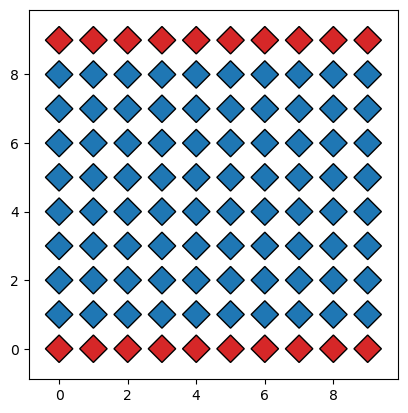

In [9]:
meta.plotvs2(vs,qs[0])

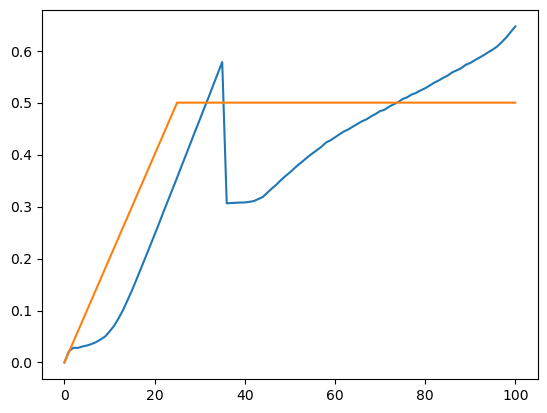

In [155]:
boundaryStress=makePressureMeasurement(bot_boundary,borderPotential)
v_boundaryStress=jax.vmap(boundaryStress,(0,None))
plt.plot(jnp.sum(v_boundaryStress(qs,sol[1]),axis=1))
plt.plot(target_stress)

In [ ]:
bot_boundary=[]
for poli in yboundary:
    if poli.y<meta.Ly/2.0:
        bot_boundary.append(poli.id)
bot_boundary=jnp.array(bot_boundary)

boundaryStress=makePressureMeasurement(bot_boundary,borderPotential)
v_boundaryStress=jax.vmap(boundaryStress,(0,None))
def makeloss1(model,w):
    def loss(vs):
        sol=model({'vs':vs,'K':K})
        qs=sol[0]
        forces=v_boundaryStress(qs,sol[1])
        force=forces[100]
        mean2=jnp.mean(force)**2
        var=jnp.mean(force**2)
        return -w*jnp.mean(forces[1])/deps/0.01/1.8+(1.0-w)*(var/mean2-1)
    return loss


#Make target stress
Nx=meta.Lx#len(boundary)-len(botboundary)-1 #estimate horizontal number of springs
Ny=meta.Ly#Ar.Ly/Ar[0].patas[0].a/2.0-1#Ar.Ly*Nx/(Ar.Lx*object_size) #estimate vertical number of springs

def get_target_Force(epsilon,epsilon_star):
    slope=Nx/Ny
    myar=np.ones(len(epsilon))*slope*meta.Ly*epsilon_star
    mask=epsilon<epsilon_star
    myar[mask]=slope*meta.Ly*epsilon[mask]
    return myar

strain=np.linspace(0,tot_strain,meta.strain_steps)
target_stress=get_target_Force(strain,0.03) #get the target force as a function of a point of buckling, force is thought to be normalized by K

l0Length=makeWeightMeasurement(meta)
def makeloss2(model,w):
    def loss(args):
        sol=model(args) #{'vs':vs,'K':K}
        qs=sol[0]
        forces=v_boundaryStress(qs,sol[1])
        stress=jnp.sum(forces,axis=1)
        return w*(2-jnp.sum(l0Length(args['vs'])/meta.PNbonds/2.0)*2.0)/2.0+(1-w)*jnp.mean((stress-target_stress)**2)*10.0
    return loss

myloss=jax.jit(makeloss2(model,0.5))
mylossgrad=jax.jit(jax.grad(myloss))


In [157]:
vs_len=len(vs) #run at least one test before

#create array of ids to measure edge size
edgeIds=[]
for poli in meta.Ar[:meta.P]:#only for a strip of edges
    patas=poli.patas
    pataSize=len(patas)
    
    for ii in range(pataSize):
        edgeIds.append([patas[ii].vid,patas[(ii+1)%pataSize].vid])
edgeIds=jnp.array(edgeIds)

#create array of ids to measure angle size
angleIds=[]
for poli in meta.Ar[:meta.P]:#only for a strip of edges
    patas=poli.patas
    pataSize=len(patas)
    for ii in range(pataSize):
        angleIds.append([patas[(ii-1)%pataSize].vid,patas[ii].vid,patas[(ii+1)%pataSize].vid])
angleIds=jnp.array(angleIds)


def edgeLength(x):
    vs=x[:vs_len]
    vsx=vs.at[0::2].get()
    vsy=vs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)[meta.vs_index]
    Avecs=meta.Avecs+nvs
    edges=Avecs[edgeIds]
    return -norm(edges[:,1]-edges[:,0],axis=1) +0.05 #NLOPT needs negative constraints
edgeLengthJit=jax.jit(edgeLength)
edgeLengthgrad=jax.jit(jax.jacobian(edgeLengthJit))
def edgeConstraint(result,x,grad):
    if grad.size > 0:
        grad[:]=edgeLengthgrad(x)
    result[:]=edgeLengthJit(x)


div=jax.vmap(lambda a,b:a/b,(0,0))
dot=jax.vmap(lambda a,b:jnp.dot(a,b),(0,0))
def l0dir(x):
    vs=x[:vs_len]
    vsx=vs.at[0::2].get()
    vsy=vs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)[meta.vs_index]
    Avecs=meta.Avecs+nvs
    rAvecs=Avecs[meta.CvertexAll[:meta.PNbonds]]
    qx=meta.q.at[meta.CqAll[:meta.PNbonds]*3+0].get()
    dqx=qx[:,0]-qx[:,1]
    dqx=dqx-meta.Lx*jnp.round(dqx/meta.Lx)
    qy=meta.q.at[meta.CqAll[:meta.PNbonds]*3+1].get()
    dqy=qy[:,0]-qy[:,1]
    dqy=dqy-meta.Ly*jnp.round(dqy/meta.Ly) 
    dqvecs=jnp.stack((dqx,dqy),axis=1)
    l0s=rAvecs[:,0,:]-rAvecs[:,1,:]+dqvecs
    nqvec=div(dqvecs,norm(dqvecs,axis=1))
    return -dot(l0s,nqvec)+0.01
l0dirJit=jax.jit(l0dir)
l0dirgrad=jax.jit(jax.jacobian(l0dirJit))
def l0Constraint(result,x,grad):
    if grad.size > 0:
        grad[:]=l0dirgrad(x)
    result[:]=l0dirJit(x)


def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi/2 , pi*3/2)
    return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi/2) % (2*jnp.pi) - jnp.pi/2
angleMap=jax.vmap( lambda d,avec,u: angleVecs(u-avec,d-avec))
def angleLength(x):
    vs=x[:vs_len]
    vsx=vs.at[0::2].get()
    vsy=vs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)[meta.vs_index]
    Avecs=meta.Avecs+nvs
    cornerVecs=Avecs[angleIds]
    return -angleMap(cornerVecs[:,0],cornerVecs[:,1],cornerVecs[:,2])+0.35#+1.57/2.0#+0.1745*2 # 0.35->20degree
angleLengthJit=jax.jit(angleLength)
angleLengthgrad=jax.jit(jax.jacobian(angleLengthJit))
def angleConstraint(result,x,grad):
    if grad.size > 0:
        grad[:]=angleLengthgrad(x)
    result[:]=angleLengthJit(x)


In [158]:
def myfunc(x, grad):
    vs=x[:vs_len]
    K=x[vs_len:]
    args={'vs':vs,'K':K}
    if grad.size > 0:
        result=mylossgrad(args)
        grad[:]=jnp.concat((result['vs'],result['K']))
    return float(myloss(args))

feature_size=len(vs)+len(K)
lower_bound=np.array(feature_size*[-10.0])
lower_bound[vs_len:]=-1e-10 #set K bound 
opt = nlopt.opt(nlopt.LD_MMA , feature_size) #NLOPT_LD_MMA
opt.set_lower_bounds(lower_bound)
opt.set_min_objective(myfunc)
constraint_tolerance=0.02
opt.add_inequality_mconstraint(edgeConstraint, meta.PNbonds*2*[constraint_tolerance])
opt.add_inequality_mconstraint(l0Constraint, meta.PNbonds*[0.01])
opt.add_inequality_mconstraint(angleConstraint, meta.PNbonds*2*[constraint_tolerance])
#opt.add_inequality_constraint(lambda x,grad: myconstraint(x,grad,-1,1), 1e-8)
opt.set_xtol_rel(1e-7)
opt.set_maxtime(60*10)

In [159]:
x=jnp.concat((vs,K))
new_x = jnp.array(opt.optimize(x))

In [160]:
new_vs=new_x[:vs_len]
new_K=new_x[vs_len:]
print(jnp.sum((new_vs-vs)**2),jnp.sum((new_K-K)**2))


0.023265565 0.0060100313


In [12]:
new_vs=new_x[:vs_len]
new_K=new_x[vs_len:]
print(jnp.sum((new_vs-vs)**2),jnp.sum((new_K-K)**2))


0.021090291 0.062260665


In [161]:
sol=model({'vs':new_vs,'K':new_K})
qs=sol[0]

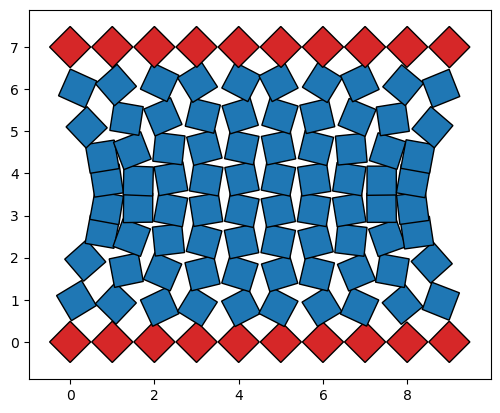

In [163]:
meta.plotvs2(jnp.array(new_vs),qs[100])

In [166]:
new_K

Array([ 1.0542262e-02,  1.9575389e-02,  5.4985873e-02,  1.6967805e-02,
        4.7326325e-03,  7.2490075e-03,  1.4675171e-02,  1.3061400e-02,
        1.5732912e-02,  1.3221971e-02,  1.6097900e-02,  1.1166347e-02,
        1.0816098e-02,  6.0674828e-03,  5.1804171e-03,  6.0095702e-04,
        3.0506984e-04,  2.3041861e-03,  2.9584859e-04,  7.1954081e-04,
        1.2012557e-03,  3.3941162e-03,  6.3875890e-03,  6.4428784e-03,
        5.0638062e-03,  4.5973989e-03,  6.2335627e-03,  8.5024890e-03,
        8.1061460e-03,  6.1000786e-03,  2.9396608e-03,  2.0516808e-03,
        6.1495102e-04,  4.6475688e-03,  1.5775629e-05,  1.2846252e-04,
        8.9192804e-04,  2.7908431e-03,  3.7854337e-03,  4.3633566e-03,
        4.3084933e-03,  5.5573643e-03,  6.4316615e-03,  5.7163578e-03,
        4.6355291e-03,  3.8572610e-03,  3.7137924e-03,  2.6148339e-03,
        1.1530317e-03,  2.2994886e-04,  7.4271913e-05,  2.2555418e-04,
        3.6713845e-04,  1.2613399e-03,  1.2312627e-03,  3.2836418e-03,
      

In [168]:
#Scores:

sol=model({'vs':new_vs,'K':new_K}) #{'vs':vs,'K':K}
qs=sol[0]
forces=v_boundaryStress(qs,sol[1])
stress=jnp.sum(forces,axis=1)
print((2-jnp.sum(l0Length(new_vs)/meta.PNbonds*2))/2.0,jnp.mean((stress-target_stress)**2)*10.0)


0.9772293 0.15561002


In [169]:
#Scores:

sol=model({'vs':vs,'K':K}) #{'vs':vs,'K':K}
qs=sol[0]
forces=v_boundaryStress(qs,sol[1])
stress=jnp.sum(forces,axis=1)
print((2-jnp.sum(l0Length(vs)/meta.PNbonds*2))/2.0,jnp.mean((stress-target_stress)**2)*10.0)

0.99 0.120264225


In [73]:
meta.makeVideo2(vs,qs,'l0test0.8/')

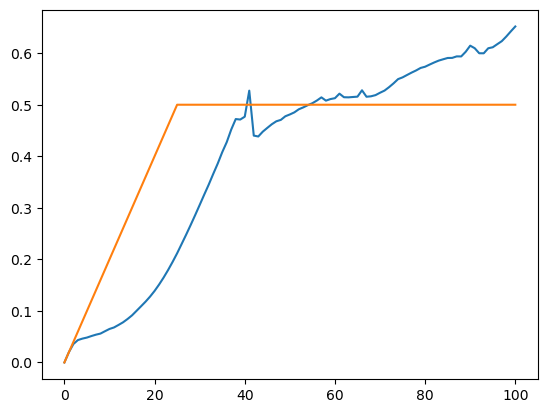

In [167]:
boundaryStress=makePressureMeasurement(bot_boundary,borderPotential)
v_boundaryStress=jax.vmap(boundaryStress,(0,None))
plt.plot(jnp.sum(v_boundaryStress(qs,sol[1]),axis=1))
plt.plot(target_stress)

In [ ]:
new_x2 = jnp.array(opt.optimize(new_x))


In [133]:
new_vs=new_x2[:vs_len]
new_K=new_x2[vs_len:]
sol2=model({'vs':new_vs,'K':new_K})
qs2=sol2[0]

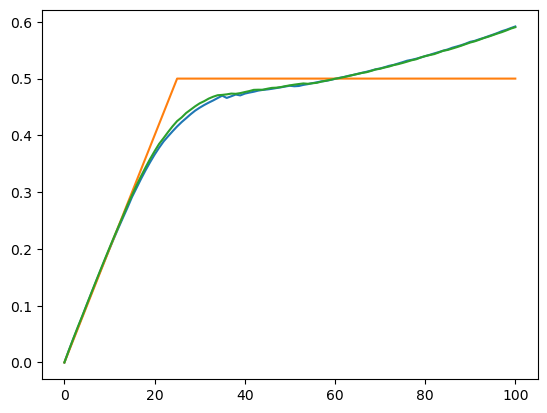

In [134]:
boundaryStress=makePressureMeasurement(bot_boundary,borderPotential)
v_boundaryStress=jax.vmap(boundaryStress,(0,None))
plt.plot(jnp.sum(v_boundaryStress(qs,sol[1]),axis=1))
plt.plot(target_stress)
plt.plot(jnp.sum(v_boundaryStress(qs2,sol2[1]),axis=1))

In [71]:
meta.PNbonds

400

In [14]:
nvs=vs[:vs_len]
vsx=nvs.at[0::2].get()
vsy=nvs.at[1::2].get()
nvs=jnp.stack((vsx,vsy),axis=1)[meta.vs_index]
Avecs=meta.Avecs+nvs
rAvecs=Avecs[meta.Cvertex[:2*meta.NbTotal//meta.Pb]]
qx=meta.q.at[meta.Cq[:meta.P]*3+0].get()
qy=meta.q.at[meta.Cq[:meta.P]*3+1].get()
qvecs=jnp.stack((qx,qy),axis=2)
dqvecs=qvecs[:,0,:]-qvecs[:,1,:]

In [15]:
qvecs.shape

(20, 2, 2)

In [16]:
2*meta.NbTotal//meta.Pb

80

In [33]:

def g(additional_info=[]):

    return f(*additional_info)


def f(arg1,arg2,arg3,arg4):
    return arg1*arg2*arg3*arg4


args=[1,2,3,4]


f(*args)

g(additional_info=args)

In [32]:
fg(posi,*args,key=1,key2=1,**kwargs)

24

In [34]:
kwargs={'asdf':10,'k1':5,'k2':3,'k4':5,'k6':5,}

24

In [ ]:
def g(k1,k2,k4,k6,asdf):



g(**kwargs)

In [36]:
values=jnp.array(args)

In [38]:
def f(args):
    return args[2:5]

In [39]:
f(values)

Array([3, 4], dtype=int32)

In [40]:
jax.jit(f)(values)

Array([3, 4], dtype=int32)

In [171]:
47/16

2.9375

In [ ]:
density=density.at[tfarry].set(1.0)

In [17]:
qx=meta.q.at[meta.CqAll[:meta.PNbonds]*3+0].get()
qx=qx-meta.Lx*jnp.round(qx/meta.Lx)
qy=meta.q.at[meta.CqAll[:meta.PNbonds]*3+1].get()
qy=qy-meta.Ly*jnp.round(qy/meta.Ly) 
qvecs=jnp.stack((qx,qy),axis=2)

In [20]:
    for t in range(100):
        np.save(folder+str(j)+'_'+str(kk)+'_'+str(t),vs)
        vs = opt.optimize(vs)
        if opt.last_optimize_result()!=6:
            np.save(folder+str(j)+'_'+str(kk)+'_'+str(t+1),vs)
            break

Array([ 0., -1.], dtype=float32)